# Caso Empresarial MANACO - Diagnóstico mediante Ciencia de Datos
## Estación 2: Exploración, Indicadores y Diagnóstico Estratégico (30 minutos)

**Programa:** Ingeniería de Sistemas, Ciencia de Datos e Inteligencia de Negocios (6.° Semestre)  
**Modalidad:** Aprendizaje Basado en Retos (ABR)  
**Rol:** Equipo Consultor de Ciencia de Datos para la Gerencia General de Manaco

---

In [2]:
from IPython.display import display
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Localización robusta de la raíz del proyecto y dataset
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

raw_dir = ROOT / "data" / "raw"
archivos_xlsx = list(raw_dir.glob("*.xlsx"))
if not archivos_xlsx:
    raise FileNotFoundError(f"No se encontró ningún archivo Excel en {raw_dir.resolve()}")

archivo = archivos_xlsx[0]
print(f"Cargando archivo: {archivo.name}")
df = pd.read_excel(archivo, sheet_name="Base de Datos")

print(f"Dimensiones del dataset: {df.shape[0]} filas x {df.shape[1]} columnas.")
display(df.head())
print("\n--- Información de Columnas y Tipos ---")
df.info()
print("\n--- Valores Nulos por Campo ---")
display(df.isna().sum().to_frame("Faltantes"))

Cargando archivo: Bae de Datos MANACO - INTERMEDIO (1).xlsx
Dimensiones del dataset: 240 filas x 10 columnas.


,País_reportante,Flujo_comercial,Año,Código_SA6,Categoría_calzado,Socio_comercial,Valor_miles_USD,Cantidad_pares,Valor_USD,Valor_USD_por_par
0,España,Importación,2023,640411,Calzado deportivo con suela de caucho/plástico,Indonesia,62576.67,2075438,6.257667e+07,30.15
1,España,Importación,2024,640411,Calzado deportivo con suela de caucho/plástico,Estados Unidos,36379.51,1199546,3.637951e+07,30.33
2,España,Importación,2022,640411,Calzado deportivo con suela de caucho/plástico,Grecia,853548.06,30537251,8.535481e+08,27.95
3,España,Importación,2020,640411,Calzado deportivo con suela de caucho/plástico,Eslovaquia,166572.63,4861274,1.665726e+08,34.27
4,España,Importación,2023,640411,Calzado deportivo con suela de caucho/plástico,Italia,241958.40,11767364,2.419584e+08,20.56



--- Información de Columnas y Tipos ---
<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   País_reportante    240 non-null    str    
 1   Flujo_comercial    240 non-null    str    
 2   Año                240 non-null    int64  
 3   Código_SA6         240 non-null    int64  
 4   Categoría_calzado  240 non-null    str    
 5   Socio_comercial    240 non-null    str    
 6   Valor_miles_USD    240 non-null    float64
 7   Cantidad_pares     240 non-null    int64  
 8   Valor_USD          240 non-null    float64
 9   Valor_USD_por_par  240 non-null    float64
dtypes: float64(3), int64(3), str(4)
memory usage: 18.9 KB

--- Valores Nulos por Campo ---


,Faltantes
País_reportante,0
Flujo_comercial,0
Año,0
Código_SA6,0
Categoría_calzado,0
Socio_comercial,0
Valor_miles_USD,0
Cantidad_pares,0
Valor_USD,0
Valor_USD_por_par,0


### 1. Indicadores Globales y Regla del Valor por Par Ponderado

**Regla Fundamental:**  
$$\text{Valor por Par Ponderado} = \frac{\sum \text{Valor Comercial USD}}{\sum \text{Cantidad Pares}}$$
*Evitar el promedio simple de la columna unitaria `Valor_USD_por_par`.*

In [3]:
from IPython.display import display
resumen_flujo = df.groupby("Flujo_comercial").agg(
    Registros=("Valor_USD", "count"),
    Valor_Total_USD=("Valor_USD", "sum"),
    Cantidad_Total_Pares=("Cantidad_pares", "sum"),
    Promedio_Simple_Unitario=("Valor_USD_por_par", "mean")
).reset_index()

resumen_flujo["Valor_por_Par_Ponderado"] = (resumen_flujo["Valor_Total_USD"] / resumen_flujo["Cantidad_Total_Pares"]).round(2)
resumen_flujo["Valor_Millones_USD"] = (resumen_flujo["Valor_Total_USD"] / 1e6).round(2)
resumen_flujo["Pares_Millones"] = (resumen_flujo["Cantidad_Total_Pares"] / 1e6).round(2)

display(resumen_flujo[["Flujo_comercial", "Registros", "Valor_Millones_USD", "Pares_Millones", "Valor_por_Par_Ponderado", "Promedio_Simple_Unitario"]])

deficit_usd = resumen_flujo.loc[resumen_flujo["Flujo_comercial"]=="Importación", "Valor_Total_USD"].values[0] - \
              resumen_flujo.loc[resumen_flujo["Flujo_comercial"]=="Exportación", "Valor_Total_USD"].values[0]
print(f"Déficit comercial global: ${deficit_usd/1e6:,.2f} Millones de USD a favor de las importaciones.")

,Flujo_comercial,Registros,Valor_Millones_USD,Pares_Millones,Valor_por_Par_Ponderado,Promedio_Simple_Unitario
0,Exportación,120,10917.35,410.77,26.58,35.111583
1,Importación,120,18506.09,751.09,24.64,37.713250


Déficit comercial global: $7,588.74 Millones de USD a favor de las importaciones.


In [4]:
from IPython.display import display
# 1. Cobertura de la base
for columna in ["País_reportante", "Año", "Flujo_comercial"]:
    print(f"\n{columna}:")
    print(df[columna].value_counts().sort_index())

# 2. Identificar registros agregados "Mundo"
es_mundo = (
    df["Socio_comercial"]
    .astype(str)
    .str.strip()
    .str.casefold()
    .eq("mundo")
)

print("\nRegistros Mundo:", es_mundo.sum())
print("Otros registros:", (~es_mundo).sum())
print("\nSocios disponibles:")
print(sorted(df["Socio_comercial"].unique()))

# 3. Revisar posibles duplicados con la clave completa
clave = [
    "País_reportante",
    "Año",
    "Código_SA6",
    "Flujo_comercial",
    "Socio_comercial",
]

repetidos = df[df.duplicated(subset=clave, keep=False)]

print("\nFilas con clave repetida:", len(repetidos))
display(repetidos.sort_values(clave))

# 4. Revisar valores que impiden o requieren revisar el cálculo
print("\nCantidades menores o iguales a cero:",
      (df["Cantidad_pares"] <= 0).sum())
print("Valores comerciales negativos:",
      (df["Valor_USD"] < 0).sum())

# 5. Resumen del detalle, separado por reportante, año y flujo
# Confirmar que los demás socios son países antes de interpretarlo.
detalle = df.loc[~es_mundo].copy()

resumen = (
    detalle.groupby(
        ["País_reportante", "Año", "Flujo_comercial"],
        as_index=False
    )
    .agg(
        registros=("Valor_USD", "size"),
        valor_usd=("Valor_USD", "sum"),
        cantidad_pares=("Cantidad_pares", "sum"),
    )
)

display(resumen)


País_reportante:
País_reportante
España    240
Name: count, dtype: int64

Año:
Año
2020    28
2021    34
2022    46
2023    50
2024    82
Name: count, dtype: int64

Flujo_comercial:
Flujo_comercial
Exportación    120
Importación    120
Name: count, dtype: int64

Registros Mundo: 0
Otros registros: 240

Socios disponibles:
['Alemania', 'Austria', 'Bangladesh', 'Brasil', 'Bélgica', 'Camboya', 'China', 'Croacia', 'Dinamarca', 'Eslovaquia', 'Eslovenia', 'Estados Unidos', 'Finlandia', 'Francia', 'Grecia', 'Hungría', 'India', 'Indonesia', 'Irlanda', 'Italia', 'Marruecos', 'Países Bajos', 'Polonia', 'Portugal', 'República Checa', 'Rumanía', 'Suecia', 'Suiza', 'Turquía', 'Vietnam']

Filas con clave repetida: 20


,País_reportante,Flujo_comercial,Año,Código_SA6,Categoría_calzado,Socio_comercial,Valor_miles_USD,Cantidad_pares,Valor_USD,Valor_USD_por_par
87,España,Importación,2020,640399,Calzado con suela de caucho/plástico y parte s...,Finlandia,207819.81,10029654,2.078198e+08,20.72
117,España,Importación,2020,640399,Calzado con suela de caucho/plástico y parte s...,Finlandia,278066.87,12870216,2.780669e+08,21.61
48,España,Exportación,2020,640411,Calzado deportivo con suela de caucho/plástico,Estados Unidos,21696.38,901775,2.169638e+07,24.06
78,España,Exportación,2020,640411,Calzado deportivo con suela de caucho/plástico,Estados Unidos,25633.20,1584001,2.563320e+07,16.18
120,España,Exportación,2023,640399,Calzado con suela de caucho/plástico y parte s...,Austria,255074.31,12134129,2.550743e+08,21.02
150,España,Exportación,2023,640399,Calzado con suela de caucho/plástico y parte s...,Austria,69998.95,1255657,6.999895e+07,55.75
202,España,Exportación,2023,640420,Calzado con suela de cuero y parte superior de...,Bélgica,2620.35,50578,2.620350e+06,51.81
232,España,Exportación,2023,640420,Calzado con suela de cuero y parte superior de...,Bélgica,2270.08,76929,2.270076e+06,29.51
160,España,Importación,2023,640420,Calzado con suela de cuero y parte superior de...,Turquía,4724.26,62209,4.724261e+06,75.94
190,España,Importación,2023,640420,Calzado con suela de cuero y parte superior de...,Turquía,2025.54,42662,2.025543e+06,47.48



Cantidades menores o iguales a cero: 0
Valores comerciales negativos: 0


,País_reportante,Año,Flujo_comercial,registros,valor_usd,cantidad_pares
0,España,2020,Exportación,15,9.879340e+08,36828978
1,España,2020,Importación,13,1.811914e+09,77095383
2,España,2021,Exportación,19,2.521354e+09,90124065
3,España,2021,Importación,15,1.430185e+09,98392100
4,España,2022,Exportación,18,1.613911e+09,59493326
5,España,2022,Importación,28,6.385527e+09,241446512
6,España,2023,Exportación,26,3.140224e+09,129958817
7,España,2023,Importación,24,1.190210e+09,45588516
8,España,2024,Exportación,42,2.653926e+09,94366461
9,España,2024,Importación,40,7.688256e+09,288566407


In [5]:
from IPython.display import display
df_validado = df.copy()

# Número de fila en Excel: la primera fila contiene encabezados.
df_validado["fila_origen"] = range(2, len(df_validado) + 2)

clave = [
    "País_reportante",
    "Año",
    "Código_SA6",
    "Flujo_comercial",
    "Socio_comercial",
]

df_validado["clave_repetida"] = df_validado.duplicated(
    subset=clave,
    keep=False
)

print("Duplicados exactos en las 10 columnas originales:",
      df.duplicated().sum())

print("Combinaciones dimensionales repetidas:",
      df_validado.loc[
          df_validado["clave_repetida"], clave
      ].drop_duplicates().shape[0])

display(
    df_validado.loc[df_validado["clave_repetida"]]
    .sort_values(clave)
)

Duplicados exactos en las 10 columnas originales: 0
Combinaciones dimensionales repetidas: 10


,País_reportante,Flujo_comercial,Año,Código_SA6,Categoría_calzado,Socio_comercial,Valor_miles_USD,Cantidad_pares,Valor_USD,Valor_USD_por_par,fila_origen,clave_repetida
87,España,Importación,2020,640399,Calzado con suela de caucho/plástico y parte s...,Finlandia,207819.81,10029654,2.078198e+08,20.72,89,True
117,España,Importación,2020,640399,Calzado con suela de caucho/plástico y parte s...,Finlandia,278066.87,12870216,2.780669e+08,21.61,119,True
48,España,Exportación,2020,640411,Calzado deportivo con suela de caucho/plástico,Estados Unidos,21696.38,901775,2.169638e+07,24.06,50,True
78,España,Exportación,2020,640411,Calzado deportivo con suela de caucho/plástico,Estados Unidos,25633.20,1584001,2.563320e+07,16.18,80,True
120,España,Exportación,2023,640399,Calzado con suela de caucho/plástico y parte s...,Austria,255074.31,12134129,2.550743e+08,21.02,122,True
150,España,Exportación,2023,640399,Calzado con suela de caucho/plástico y parte s...,Austria,69998.95,1255657,6.999895e+07,55.75,152,True
202,España,Exportación,2023,640420,Calzado con suela de cuero y parte superior de...,Bélgica,2620.35,50578,2.620350e+06,51.81,204,True
232,España,Exportación,2023,640420,Calzado con suela de cuero y parte superior de...,Bélgica,2270.08,76929,2.270076e+06,29.51,234,True
160,España,Importación,2023,640420,Calzado con suela de cuero y parte superior de...,Turquía,4724.26,62209,4.724261e+06,75.94,162,True
190,España,Importación,2023,640420,Calzado con suela de cuero y parte superior de...,Turquía,2025.54,42662,2.025543e+06,47.48,192,True


### 2. Gráfico 1: Importaciones frente a Exportaciones por Año (2020 - 2024)
Evolución comparativa del comercio exterior registrado.

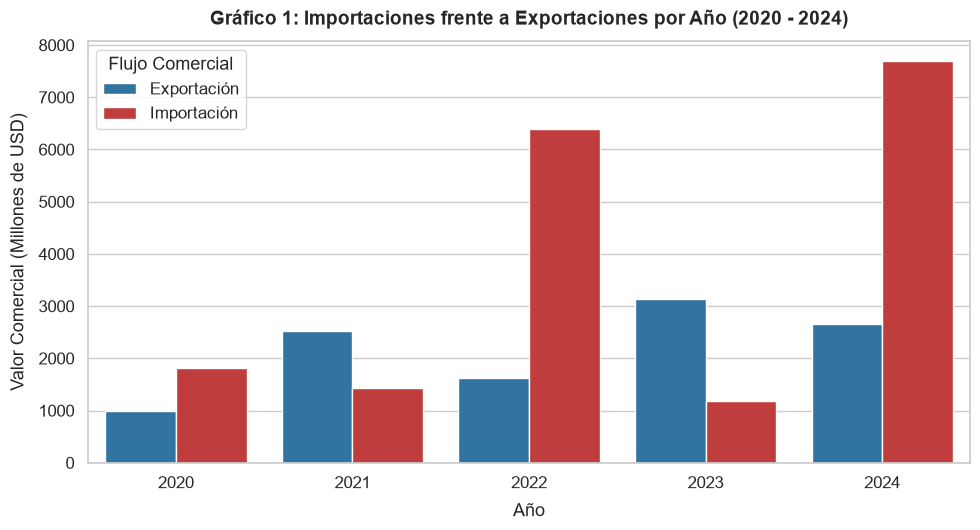

In [5]:
plt.figure(figsize=(10, 5.5))
sns.set_theme(style="whitegrid", font_scale=1.1)

anual = df.groupby(["Año", "Flujo_comercial"])["Valor_USD"].sum().reset_index()
anual["Valor_Millones"] = anual["Valor_USD"] / 1e6

sns.barplot(data=anual, x="Año", y="Valor_Millones", hue="Flujo_comercial", palette=["#1f77b4", "#d62728"])
plt.title("Gráfico 1: Importaciones frente a Exportaciones por Año (2020 - 2024)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Año", labelpad=8)
plt.ylabel("Valor Comercial (Millones de USD)", labelpad=8)
plt.legend(title="Flujo Comercial", frameon=True)
plt.tight_layout()
plt.show()

### 3. Gráfico 2: Principales Socios Comerciales por Valor de Importación
Identificación de la concentración geográfica en proveedores.

In [ ]:
plt.figure(figsize=(10, 6))
top_socios = df[df["Flujo_comercial"] == "Importación"].groupby("Socio_comercial")["Valor_USD"].sum().reset_index()
top_socios["Valor_Millones"] = top_socios["Valor_USD"] / 1e6
top_socios = top_socios.sort_values(by="Valor_Millones", ascending=False).head(10)

sns.barplot(data=top_socios, x="Valor_Millones", y="Socio_comercial", hue="Socio_comercial", palette="Blues_r", legend=False)
plt.title("Gráfico 2: Top 10 Socios Comerciales por Valor de Importación (Millones USD)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Valor Importado (Millones de USD)", labelpad=8)
plt.ylabel("Socio Comercial", labelpad=8)
plt.tight_layout()
plt.show()

### 4. Gráfico 3: Comparación de Valor por Par por Categoría de Calzado
Diferenciación entre el calzado sintético/deportivo y el calzado de cuero.

In [ ]:
cat = df.groupby(["Categoría_calzado", "Flujo_comercial"]).agg(
    Valor_Total=("Valor_USD", "sum"),
    Pares_Total=("Cantidad_pares", "sum")
).reset_index()
cat["Valor_por_Par"] = cat["Valor_Total"] / cat["Pares_Total"]
cat["Categoria_Corta"] = cat["Categoría_calzado"].map({
    "Calzado deportivo con suela de caucho/plástico": "Deportivo (Caucho/Plástico)",
    "Calzado con suela de caucho/plástico y parte superior de cuero": "Suela Sintética / Cuero",
    "Calzado con suela de cuero y parte superior de cuero/material similar": "Suela Cuero / Cuero"
})

plt.figure(figsize=(11, 5.5))
sns.barplot(data=cat, x="Categoria_Corta", y="Valor_por_Par", hue="Flujo_comercial", palette=["#2ca02c", "#ff7f0e"])
plt.title("Gráfico 3: Comparación de Valor Comercial Ponderado por Par (USD/Par)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Categoría de Calzado", labelpad=8)
plt.ylabel("Valor Comercial Ponderado (USD / Par)", labelpad=8)
plt.legend(title="Flujo Comercial", frameon=True)
plt.tight_layout()
plt.show()

## 5. Síntesis Ejecutiva (Defensa del Reto)

### Tres Hallazgos Clave:
1. **Déficit Estructural y Crecimiento de Importaciones:** Las importaciones ($18,506 M USD) superan a las exportaciones ($10,917 M USD) en un 69.5% en valor y un 82.8% en pares, con saltos críticos en 2022 y 2024.
2. **Divergencia Valor vs. Cantidad:** El calzado deportivo y sintético acapara el 98.7% del volumen importado compitiendo a precios bajos ($23-$26 USD/par), mientras que el calzado con suela de cuero alcanza más de $45 USD/par pero con apenas el 1% de los pares.
3. **Concentración de Socios:** Grecia, Países Bajos y Vietnam concentran los mayores volúmenes de importación, confirmando la presión de centros logísticos y fábricas asiáticas.

### Dos Limitaciones:
1. **Valor Aduanero vs. Precio al Consumidor:** El valor aduanero por par es CIF/FOB en frontera; no incluye márgenes del retail, impuestos ni fletes internos (no equivale al precio en tienda).
2. **Carencia de Datos Internos:** El dataset es de referencia de mercado; para diagnosticar a Manaco con precisión se debe cruzar con su ERP de costos de fábrica y POS de tiendas.

### Pregunta Estratégica para Manaco:
> *"¿Debe Manaco reenfocar su producción fabril exclusivamente hacia el segmento de cuero de alta gama (donde el mercado convalida valores de más de $40-$45 USD/par), dejando la línea deportiva de bajo margen para maquila o distribución externa?"*